In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
print("Hello Kaggle!")

Hello Kaggle!


In [3]:

import os

possible_roots = [
    "/kaggle/input/competitions/airbus-ship-detection",
    "/kaggle/input/airbus-ship-detection",
]

DATA_DIR = None

for path in possible_roots:
    if os.path.isdir(path):
        DATA_DIR = path
        break

if DATA_DIR is None:
    print("Dataset folder not found in the expected locations.")
    print("Available top-level input folders:")
    print(os.listdir("/kaggle/input"))
else:
    print("Dataset folder:", DATA_DIR)
    print("Files and folders at dataset root:")
    print(os.listdir(DATA_DIR)[:30])


Dataset folder: /kaggle/input/competitions/airbus-ship-detection
Files and folders at dataset root:
['test_v2', 'sample_submission_v2.csv', 'train_ship_segmentations_v2.csv', 'train_v2']


In [4]:

# Install only if a required package is missing.
import importlib.util
import subprocess
import sys

required = {
    "mahotas": "mahotas",
    "xgboost": "xgboost",
    "cv2": "opencv-python-headless",
}

for module, package in required.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", package
        ])

import os
import glob
import cv2
import mahotas
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

print("XGBoost version:", xgb.__version__)

# Find the labels CSV in the dataset's root directory.
csv_candidates = [
    os.path.join(DATA_DIR, "train_ship_segmentations_v2.csv"),
    os.path.join(DATA_DIR, "train_ship_segmentations.csv"),
]

CSV_PATH = next(
    (p for p in csv_candidates if os.path.isfile(p)),
    None
)

if CSV_PATH is None:
    print("CSV not found. Root entries:", os.listdir(DATA_DIR)[:30])
else:
    print("Labels CSV:", CSV_PATH)

# Find the training images directory.
image_dir_candidates = [
    os.path.join(DATA_DIR, "train_v2"),
    os.path.join(DATA_DIR, "train"),
]

IMAGE_DIR = next(
    (p for p in image_dir_candidates if os.path.isdir(p)),
    None
)

if IMAGE_DIR is None:
    print("Training image folder not found.")
else:
    print("Training images folder:", IMAGE_DIR)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 6.3 MB/s eta 0:00:00
XGBoost version: 3.4.1
Labels CSV: /kaggle/input/competitions/airbus-ship-detection/train_ship_segmentations_v2.csv
Training images folder: /kaggle/input/competitions/airbus-ship-detection/train_v2


In [5]:

if CSV_PATH is None or IMAGE_DIR is None:
    raise FileNotFoundError(
        "Please fix the CSV or image folder path before continuing."
    )

labels_df = pd.read_csv(CSV_PATH)

print("CSV rows:", len(labels_df))
print("CSV columns:", labels_df.columns.tolist())

required_columns = {"ImageId", "EncodedPixels"}
if not required_columns.issubset(labels_df.columns):
    raise ValueError(
        f"Expected columns {required_columns}, "
        f"but found {labels_df.columns.tolist()}"
    )

# A non-null mask means that a ship is present.
labels_df["has_ship"] = labels_df["EncodedPixels"].notna().astype("uint8")

# Combine multiple ship-mask rows into one image-level label.
image_labels = (
    labels_df.groupby("ImageId")["has_ship"]
    .max()
    .astype("uint8")
)

print("\nUnique labeled images:", len(image_labels))
print("\nClass counts:")
print(image_labels.value_counts().rename(index={0: "No ship", 1: "Ship"}))
print("\nClass proportions:")
print(image_labels.value_counts(normalize=True).sort_index())


CSV rows: 231723
CSV columns: ['ImageId', 'EncodedPixels']

Unique labeled images: 192556

Class counts:
has_ship
No ship    150000
Ship        42556
Name: count, dtype: int64

Class proportions:
has_ship
0    0.778994
1    0.221006
Name: proportion, dtype: float64


In [11]:

import os
import cv2
import numpy as np
import pandas as pd

DATA_DIR = "/kaggle/input/competitions/airbus-ship-detection"
CSV_PATH = os.path.join(DATA_DIR, "train_ship_segmentations_v2.csv")
IMAGE_DIR = os.path.join(DATA_DIR, "train_v2")

# Match the teammate's image-level labels and sampling procedure.
df = pd.read_csv(CSV_PATH)

lab = (
    df.groupby("ImageId")["EncodedPixels"]
      .apply(lambda s: int(s.notna().any()))
      .reset_index(name="has_ship")
)

N_TRAIN = 7000
N_DEV = 3000
N_TEST = 5000
N_TOTAL = N_TRAIN + N_DEV + N_TEST

# Exactly the same random seed and sampling order as her notebook.
order = np.random.default_rng(0).permutation(len(lab))

selected_ids = []
selected_y = []

for idx in order:
    row = lab.iloc[idx]
    image_path = os.path.join(IMAGE_DIR, row["ImageId"])

    # Match her readable-image check.
    image = cv2.imread(image_path)
    if image is None:
        continue

    selected_ids.append(row["ImageId"])
    selected_y.append(int(row["has_ship"]))

    if len(selected_ids) == N_TOTAL:
        break

if len(selected_ids) != N_TOTAL:
    raise RuntimeError(
        f"Expected {N_TOTAL} readable images, found {len(selected_ids)}"
    )

selected_ids = np.array(selected_ids)
selected_y = np.array(selected_y, dtype=np.uint8)

train_ids = selected_ids[:7000]
dev_ids = selected_ids[7000:10000]
test_ids = selected_ids[10000:15000]

y_train = selected_y[:7000]
y_dev = selected_y[7000:10000]
y_test = selected_y[10000:15000]

print("Train:", len(train_ids))
print("Development:", len(dev_ids))
print("Test:", len(test_ids))
print("Training ship fraction:", round(float(y_train.mean()), 4))
print("Test ship fraction:", round(float(y_test.mean()), 4))
print("First training IDs:", train_ids[:5])
print("First test IDs:", test_ids[:5])


Train: 7000
Development: 3000
Test: 5000
Training ship fraction: 0.2191
Test ship fraction: 0.2164
First training IDs: ['3ab571c31.jpg' 'acea8d3a9.jpg' 'ebd36edda.jpg' 'cdc92b484.jpg'
 '609ae1f4b.jpg']
First test IDs: ['159ec13d8.jpg' 'be7166d30.jpg' '90afa9b2b.jpg' '7315d654c.jpg'
 '2043d3825.jpg']


In [14]:

import mahotas

def extract_features_matching_paper(image_path):
    image = cv2.imread(image_path)

    if image is None:
        return None

    # Match teammate's preprocessing: resize, then convert BGR to RGB.
    image = cv2.resize(
        cv2.cvtColor(image, cv2.COLOR_BGR2RGB),
        (256, 256),
        interpolation=cv2.INTER_AREA
    )

    # 1. HSV colour histogram: 512 features.
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    hist = cv2.calcHist(
        [hsv], [0, 1, 2], None,
        [8, 8, 8],
        [0, 180, 0, 256, 0, 256]
    )
    cv2.normalize(hist, hist)

    # 2. Haralick texture: 13 features.
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    try:
        haralick = mahotas.features.haralick(gray).mean(axis=0)
    except Exception:
        haralick = np.zeros(13)

    # 3. Hu moments: 7 features.
    hu = cv2.HuMoments(cv2.moments(gray)).flatten()

    return np.concatenate([
        hist.flatten(),
        np.nan_to_num(haralick),
        hu
    ]).astype(np.float32)


In [15]:

from tqdm.auto import tqdm

def build_feature_matrix(image_ids, description):
    rows = []
    valid_ids = []
    failed_ids = []

    for image_id in tqdm(image_ids, desc=description):
        path = os.path.join(IMAGE_DIR, image_id)

        try:
            features = extract_features_matching_paper(path)

            if features is not None and np.isfinite(features).all():
                rows.append(features)
                valid_ids.append(image_id)
            else:
                failed_ids.append(image_id)
        except Exception:
            failed_ids.append(image_id)

    X = pd.DataFrame(
        rows,
        index=valid_ids,
        columns=(
            [f"color_{i}" for i in range(512)]
            + [f"haralick_{i}" for i in range(13)]
            + [f"hu_{i}" for i in range(7)]
        )
    )

    return X, valid_ids, failed_ids


X_train, valid_train_ids, failed_train = build_feature_matrix(
    train_ids, "Training feature extraction"
)

X_test, valid_test_ids, failed_test = build_feature_matrix(
    test_ids, "Test feature extraction"
)

y_train = pd.Series(
    selected_y[:7000], index=train_ids
).loc[valid_train_ids]

y_test = pd.Series(
    selected_y[10000:15000], index=test_ids
).loc[valid_test_ids]

print("Training matrix:", X_train.shape)
print("Test matrix:", X_test.shape)
print("Failed training images:", len(failed_train))
print("Failed test images:", len(failed_test))


Training feature extraction:   0%|          | 0/7000 [00:00<?, ?it/s]

Test feature extraction:   0%|          | 0/5000 [00:00<?, ?it/s]

Training matrix: (7000, 532)
Test matrix: (5000, 532)
Failed training images: 0
Failed test images: 0


,Metric,Score
0,Accuracy,0.9222
1,Precision,0.7979
2,Recall,0.8577
3,F1-score,0.8267
4,ROC-AUC,0.9688


              precision    recall  f1-score   support

     No Ship       0.96      0.94      0.95      3918
        Ship       0.80      0.86      0.83      1082

    accuracy                           0.92      5000
   macro avg       0.88      0.90      0.89      5000
weighted avg       0.92      0.92      0.92      5000



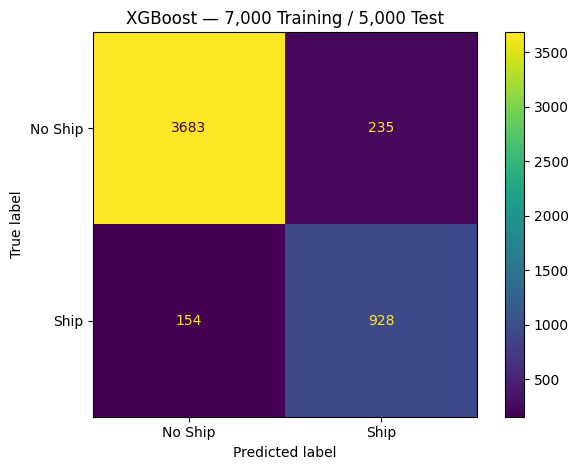

In [16]:

import xgboost as xgb

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    scale_pos_weight=negative_count / max(positive_count, 1),
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

results_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ]
})

results_df["Score"] = results_df["Score"].round(4)
display(results_df)

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No Ship", "Ship"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[0, 1],
    display_labels=["No Ship", "Ship"],
    values_format="d"
)
plt.title("XGBoost — 7,000 Training / 5,000 Test")
plt.tight_layout()
plt.show()


In [17]:

OUTPUT_DIR = "/kaggle/working"

model.save_model(
    os.path.join(OUTPUT_DIR, "airbus_xgboost_7000_5000.json")
)
results_df.to_csv(
    os.path.join(OUTPUT_DIR, "xgboost_7000_5000_metrics.csv"),
    index=False
)

pd.DataFrame({
    "ImageId": valid_test_ids,
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Ship_Probability": y_prob
}).to_csv(
    os.path.join(OUTPUT_DIR, "xgboost_7000_5000_predictions.csv"),
    index=False
)

print("Updated XGBoost model and results saved.")


Updated XGBoost model and results saved.
